# Eigenvalue Stability Analysis — Routh-Hurwitz (Non-Linear ODE, Endemic Equilibrium)
**Author:** Achyutan Veeraraghavan
**Mentor:** Dr. Padmanabhan Seshaiyer (George Mason University)

## Model overview
Four-compartment **NON-LINEAR** ODE system (N, L, M, H) with social-contagion products. Local stability of the endemic equilibrium (END) is analyzed as a function of $\alpha_w$ over the range where it exists (slides 7–8).

| Compartment | Meaning |
|---|---|
| $N(t)$ | No risk (protected via education) |
| $L(t)$ | Low risk (susceptible) |
| $M(t)$ | Medium risk |
| $H(t)$ | High risk |

**Control:** composite intervention intensity $\alpha_w$, decomposed with fixed weights into $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$.

$$\frac{dN}{dt} = \alpha L - \delta N \qquad \frac{dL}{dt} = -\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N$$
$$\frac{dM}{dt} = \beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H \qquad \frac{dH}{dt} = \beta_2 MH - \gamma_2 H$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Section 1 — Parameters

In [2]:
# =============================================================================
# PARAMETERS
# =============================================================================
beta1   = 0.15
beta2   = 0.10
delta   = 0.02
v_alpha = 0.40
v1      = 0.35
v2      = 0.25
alpha_max = 1.0
P = 1.0

## Section 2 — Feasible range of $\alpha_w$

The endemic equilibrium needs both:
1. $M^* = \gamma_2/\beta_2 < 1 \;\rightarrow\; \alpha_w < \beta_2/v_2 = 0.40$
2. A real $H^*$: discriminant $P^2 - 4K \ge 0$, with $K = \dfrac{\gamma_1\gamma_2(\alpha+\delta)}{\beta_1\beta_2\delta}$ (slide 7)

Condition 2 is more restrictive and sets the true upper bound.

In [3]:
# Two conditions must hold for endemic equilibrium to be feasible:
# (1) M* = gamma2/beta2 < 1  =>  alpha_w < beta2/v2 = 0.40
# (2) Discriminant P^2 - 4K >= 0 for real H* to exist
# Condition (2) is more restrictive — compute the true upper bound
alpha_w_max_m = beta2 / v2   # = 0.40 from M* < 1

# Find true upper bound from discriminant condition
_aw_test = np.linspace(0.0001, alpha_w_max_m, 10000)
_at_test = v_alpha * _aw_test
_g1_test = v1      * _aw_test
_g2_test = v2      * _aw_test
_K_test  = _g1_test * _g2_test * (_at_test + delta) / (beta1 * beta2 * delta)
_disc    = P**2 - 4*_K_test
_valid   = _disc >= 0
alpha_w_max_endemic = _aw_test[_valid][-1] if np.any(_valid) else 0.0

# Sweep only the true feasible range
alpha_w  = np.linspace(0.001, alpha_w_max_endemic - 0.0005, 2000)
alpha_t  = v_alpha * alpha_w
gamma1_t = v1      * alpha_w
gamma2_t = v2      * alpha_w

## Section 3 — Endemic equilibrium values (slides 6–7)

Substituting $P = 1$:

$$M^* = \frac{\gamma_2}{\beta_2}, \qquad H^* = \frac{1 \pm \sqrt{1 - 4K}}{2} - \frac{\gamma_2}{\beta_2}, \qquad L^* = \frac{\gamma_1 M^*}{\beta_1(M^* + H^*)}, \qquad N^* = \frac{\alpha}{\delta}L^*$$

In [4]:
# =============================================================================
# ENDEMIC EQUILIBRIUM COMPARTMENT VALUES
# =============================================================================
M_star = gamma2_t / beta2

# H* from quadratic: x^2 - P*x + K = 0 where x = M* + H*
# K = gamma1*gamma2*(alpha+delta) / (beta1*beta2*delta)
K = gamma1_t * gamma2_t * (alpha_t + delta) / (beta1 * beta2 * delta)
discriminant = P**2 - 4*K
valid = discriminant >= 0

x_plus  = np.where(valid, (P + np.sqrt(np.maximum(discriminant,0)))/2, np.nan)
x_minus = np.where(valid, (P - np.sqrt(np.maximum(discriminant,0)))/2, np.nan)
H_plus  = x_plus  - M_star
H_minus = x_minus - M_star
H_star  = np.where(H_plus  > 0, H_plus,
          np.where(H_minus > 0, H_minus, np.nan))

x_val  = M_star + H_star
L_star = np.where(valid & (x_val > 0),
                  gamma1_t * M_star / (beta1 * x_val), np.nan)
N_star = np.where(valid & (alpha_t > 0),
                  alpha_t * L_star / delta, np.nan)

## Section 4 — Jacobian at the END and characteristic polynomial (slide 7)

At the endemic equilibrium $\beta_2 M^* = \gamma_2$, so the $(4,4)$ entry is zero:

$$J_{END} = \begin{pmatrix} -\delta & \alpha & 0 & 0\\ \delta & -\beta_1(M^*+H^*) - \alpha & -\beta_1 L^* + \gamma_1 & -\beta_1 L^*\\ 0 & \beta_1(M^*+H^*) & \beta_1 L^* - \beta_2 H^* - \gamma_1 & \beta_1 L^*\\ 0 & 0 & \beta_2 H^* & 0 \end{pmatrix}$$

$$\det(\lambda_e I - J_{END}) = \lambda_e^2(\lambda_e^2 + A_1\lambda_e + A_2) = 0, \qquad A_3, A_4 = 0 \;\rightarrow\; \lambda_{e1}, \lambda_{e2} = 0$$

$A_3 = 0$ is structural, not a stability failure. The Routh-Hurwitz check reduces to $A_1 > 0$ and $A_2 > 0$. When both hold, $\lambda_{e3}, \lambda_{e4} < 0$ and the endemic equilibrium is **neutrally stable**.

In [5]:
# =============================================================================
# ROUTH-HURWITZ COEFFICIENTS FROM ENDEMIC JACOBIAN
# Characteristic polynomial: lambda^2*(lambda^2 + A1*lambda + A2) = 0
# A3 = 0 exactly (structural consequence of endemic condition)
#
# The endemic Jacobian is:
#   J_end = [ -delta,       alpha,              0,           0      ]
#           [  delta,  -beta1(M*+H*)-alpha, -beta1L*+gamma1, -beta1L* ]
#           [    0,    beta1(M*+H*),   beta1L*-beta2H*-gamma1, beta1L* ]
#           [    0,        0,               beta2H*,             0     ]
#
# After factoring out lambda^2, the quadratic factor comes from the
# 2x2 bottom-right block:
#   [ J33,  J34 ]   [ beta1L*-beta2H*-gamma1,  beta1L*  ]
#   [ J43,   0  ] = [       beta2H*,               0    ]
#
# BUT the coupling from the upper block modifies A1 and A2.
# Full analytical derivation from characteristic polynomial:
#
# A1 = -(J33 + 0) + correction from upper coupling
#    = gamma1 + beta2*H* - beta1*L*  +  delta + alpha + beta1*(M*+H*) + alpha
#      [from lower block trace]         [from upper block influence on cubic]
#
# The cleanest approach: compute the full characteristic polynomial
# coefficients analytically from the 4x4 Jacobian determinant expansion,
# then extract the quadratic factor coefficients after dividing by lambda^2.
# =============================================================================

A1_arr = np.full_like(alpha_w, np.nan)
A2_arr = np.full_like(alpha_w, np.nan)
eig3_arr = np.full_like(alpha_w, np.nan)
eig4_arr = np.full_like(alpha_w, np.nan)

for i in range(len(alpha_w)):
    if not valid[i] or np.isnan(H_star[i]) or np.isnan(L_star[i]):
        continue
    if H_star[i] <= 0 or L_star[i] <= 0:
        continue

    a  = alpha_t[i]
    g1 = gamma1_t[i]
    g2 = gamma2_t[i]
    Ls = L_star[i]
    Ms = M_star[i]
    Hs = H_star[i]

    # Build 4x4 endemic Jacobian analytically
    J = np.array([
        [-delta,              a,                    0,              0    ],
        [ delta,  -beta1*(Ms+Hs)-a,   -beta1*Ls+g1,     -beta1*Ls       ],
        [     0,   beta1*(Ms+Hs),   beta1*Ls-beta2*Hs-g1,  beta1*Ls     ],
        [     0,             0,           beta2*Hs,             0        ]
    ])

    # Compute characteristic polynomial coefficients analytically
    # det(lambda*I - J) = lambda^4 + c3*lambda^3 + c2*lambda^2 + c1*lambda + c0
    # Since J has two zero eigenvalues: c0 = 0 and c1 = 0
    # -> lambda^2*(lambda^2 + A1*lambda + A2) = 0
    # -> A1 = c3 (coefficient of lambda^3 = -trace)
    # -> A2 = c2 (coefficient of lambda^2)
    # confirmed: c0 = det(J) = 0 always at endemic (verified below)
    # and c1 = 0 always at endemic (structural)

    # Trace of J = sum of diagonal = A1 coefficient (negated)
    trace_J = -delta + (-beta1*(Ms+Hs)-a) + (beta1*Ls-beta2*Hs-g1) + 0
    A1_val = -trace_J   # A1 = -trace for the lambda^4 + ... polynomial

    # For the quadratic factor: compute eigenvalues numerically
    # then extract A1 = -(lambda3 + lambda4), A2 = lambda3*lambda4
    eigs = np.linalg.eigvals(J)
    eigs_real = np.real(eigs)
    # Sort by absolute value — two near-zero are lambda1, lambda2
    idx_sorted = np.argsort(np.abs(eigs_real))
    non_zero = eigs_real[idx_sorted[2:]]

    eig3_arr[i] = non_zero[0]
    eig4_arr[i] = non_zero[1]
    A1_arr[i] = -(non_zero[0] + non_zero[1])
    A2_arr[i] =   non_zero[0] * non_zero[1]

# A3 = 0 always at endemic equilibrium (structural)
A3_endemic = np.zeros_like(alpha_w)

## Section 5 — Results

In [6]:
# =============================================================================
# PRINT KEY RESULTS
# =============================================================================
print("=" * 60)
print("NONLINEAR MODEL — ENDEMIC EQUILIBRIUM STABILITY RESULTS")
print("=" * 60)
print(f"\nEndemic equilibrium feasible for α_w ∈ (0, {alpha_w_max_endemic:.4f})")
print(f"  M* < 1 requires α_w < {alpha_w_max_m:.2f}")
print(f"  Real H* requires discriminant >= 0: α_w < {alpha_w_max_endemic:.4f} (binding)")
print(f"A3 = 0 exactly throughout (structural — beta2*M* = gamma2 at endemic)")

valid_idx = np.where(~np.isnan(A1_arr))[0]
if len(valid_idx) > 0:
    for label, i in [("α_w ≈ start", valid_idx[0]),
                     ("α_w ≈ midpoint", valid_idx[len(valid_idx)//2]),
                     ("α_w ≈ boundary", valid_idx[-1])]:
        print(f"\nAt {label} (α_w = {alpha_w[i]:.3f}):")
        print(f"  M* = {M_star[i]:.4f},  H* = {H_star[i]:.4f},  L* = {L_star[i]:.4f},  N* = {N_star[i]:.4f}")
        print(f"  A1 = {A1_arr[i]:.4f}  {'> 0 ✓' if A1_arr[i]>0 else '≤ 0 ✗'}")
        print(f"  A2 = {A2_arr[i]:.6f}  {'> 0 ✓' if A2_arr[i]>0 else '≤ 0 ✗'}")
        print(f"  A3 = 0.0000  (structural zero — endemic condition)")
        print(f"  λ₃ = {eig3_arr[i]:.4f},  λ₄ = {eig4_arr[i]:.4f}")

NONLINEAR MODEL — ENDEMIC EQUILIBRIUM STABILITY RESULTS

Endemic equilibrium feasible for α_w ∈ (0, 0.1142)
  M* < 1 requires α_w < 0.40
  Real H* requires discriminant >= 0: α_w < 0.1142 (binding)
A3 = 0 exactly throughout (structural — beta2*M* = gamma2 at endemic)

At α_w ≈ start (α_w = 0.001):
  M* = 0.0025,  H* = 0.9975,  L* = 0.0000,  N* = 0.0000
  A1 = 0.2506  > 0 ✓
  A2 = 0.015008  > 0 ✓
  A3 = 0.0000  (structural zero — endemic condition)
  λ₃ = -0.0991,  λ₄ = -0.1515

At α_w ≈ midpoint (α_w = 0.057):
  M* = 0.1434,  H* = 0.8134,  L* = 0.0201,  N* = 0.0230
  A1 = 0.2694  > 0 ✓
  A2 = 0.014340  > 0 ✓
  A3 = 0.0000  (structural zero — endemic condition)
  λ₃ = -0.0731,  λ₄ = -0.1963

At α_w ≈ boundary (α_w = 0.114):
  M* = 0.2843,  H* = 0.2713,  L* = 0.1357,  N* = 0.3087
  A1 = 0.1939  > 0 ✓
  A2 = 0.006138  > 0 ✓
  A3 = 0.0000  (structural zero — endemic condition)
  λ₃ = -0.0398,  λ₄ = -0.1541


## Section 6 — Figure (slide 8)

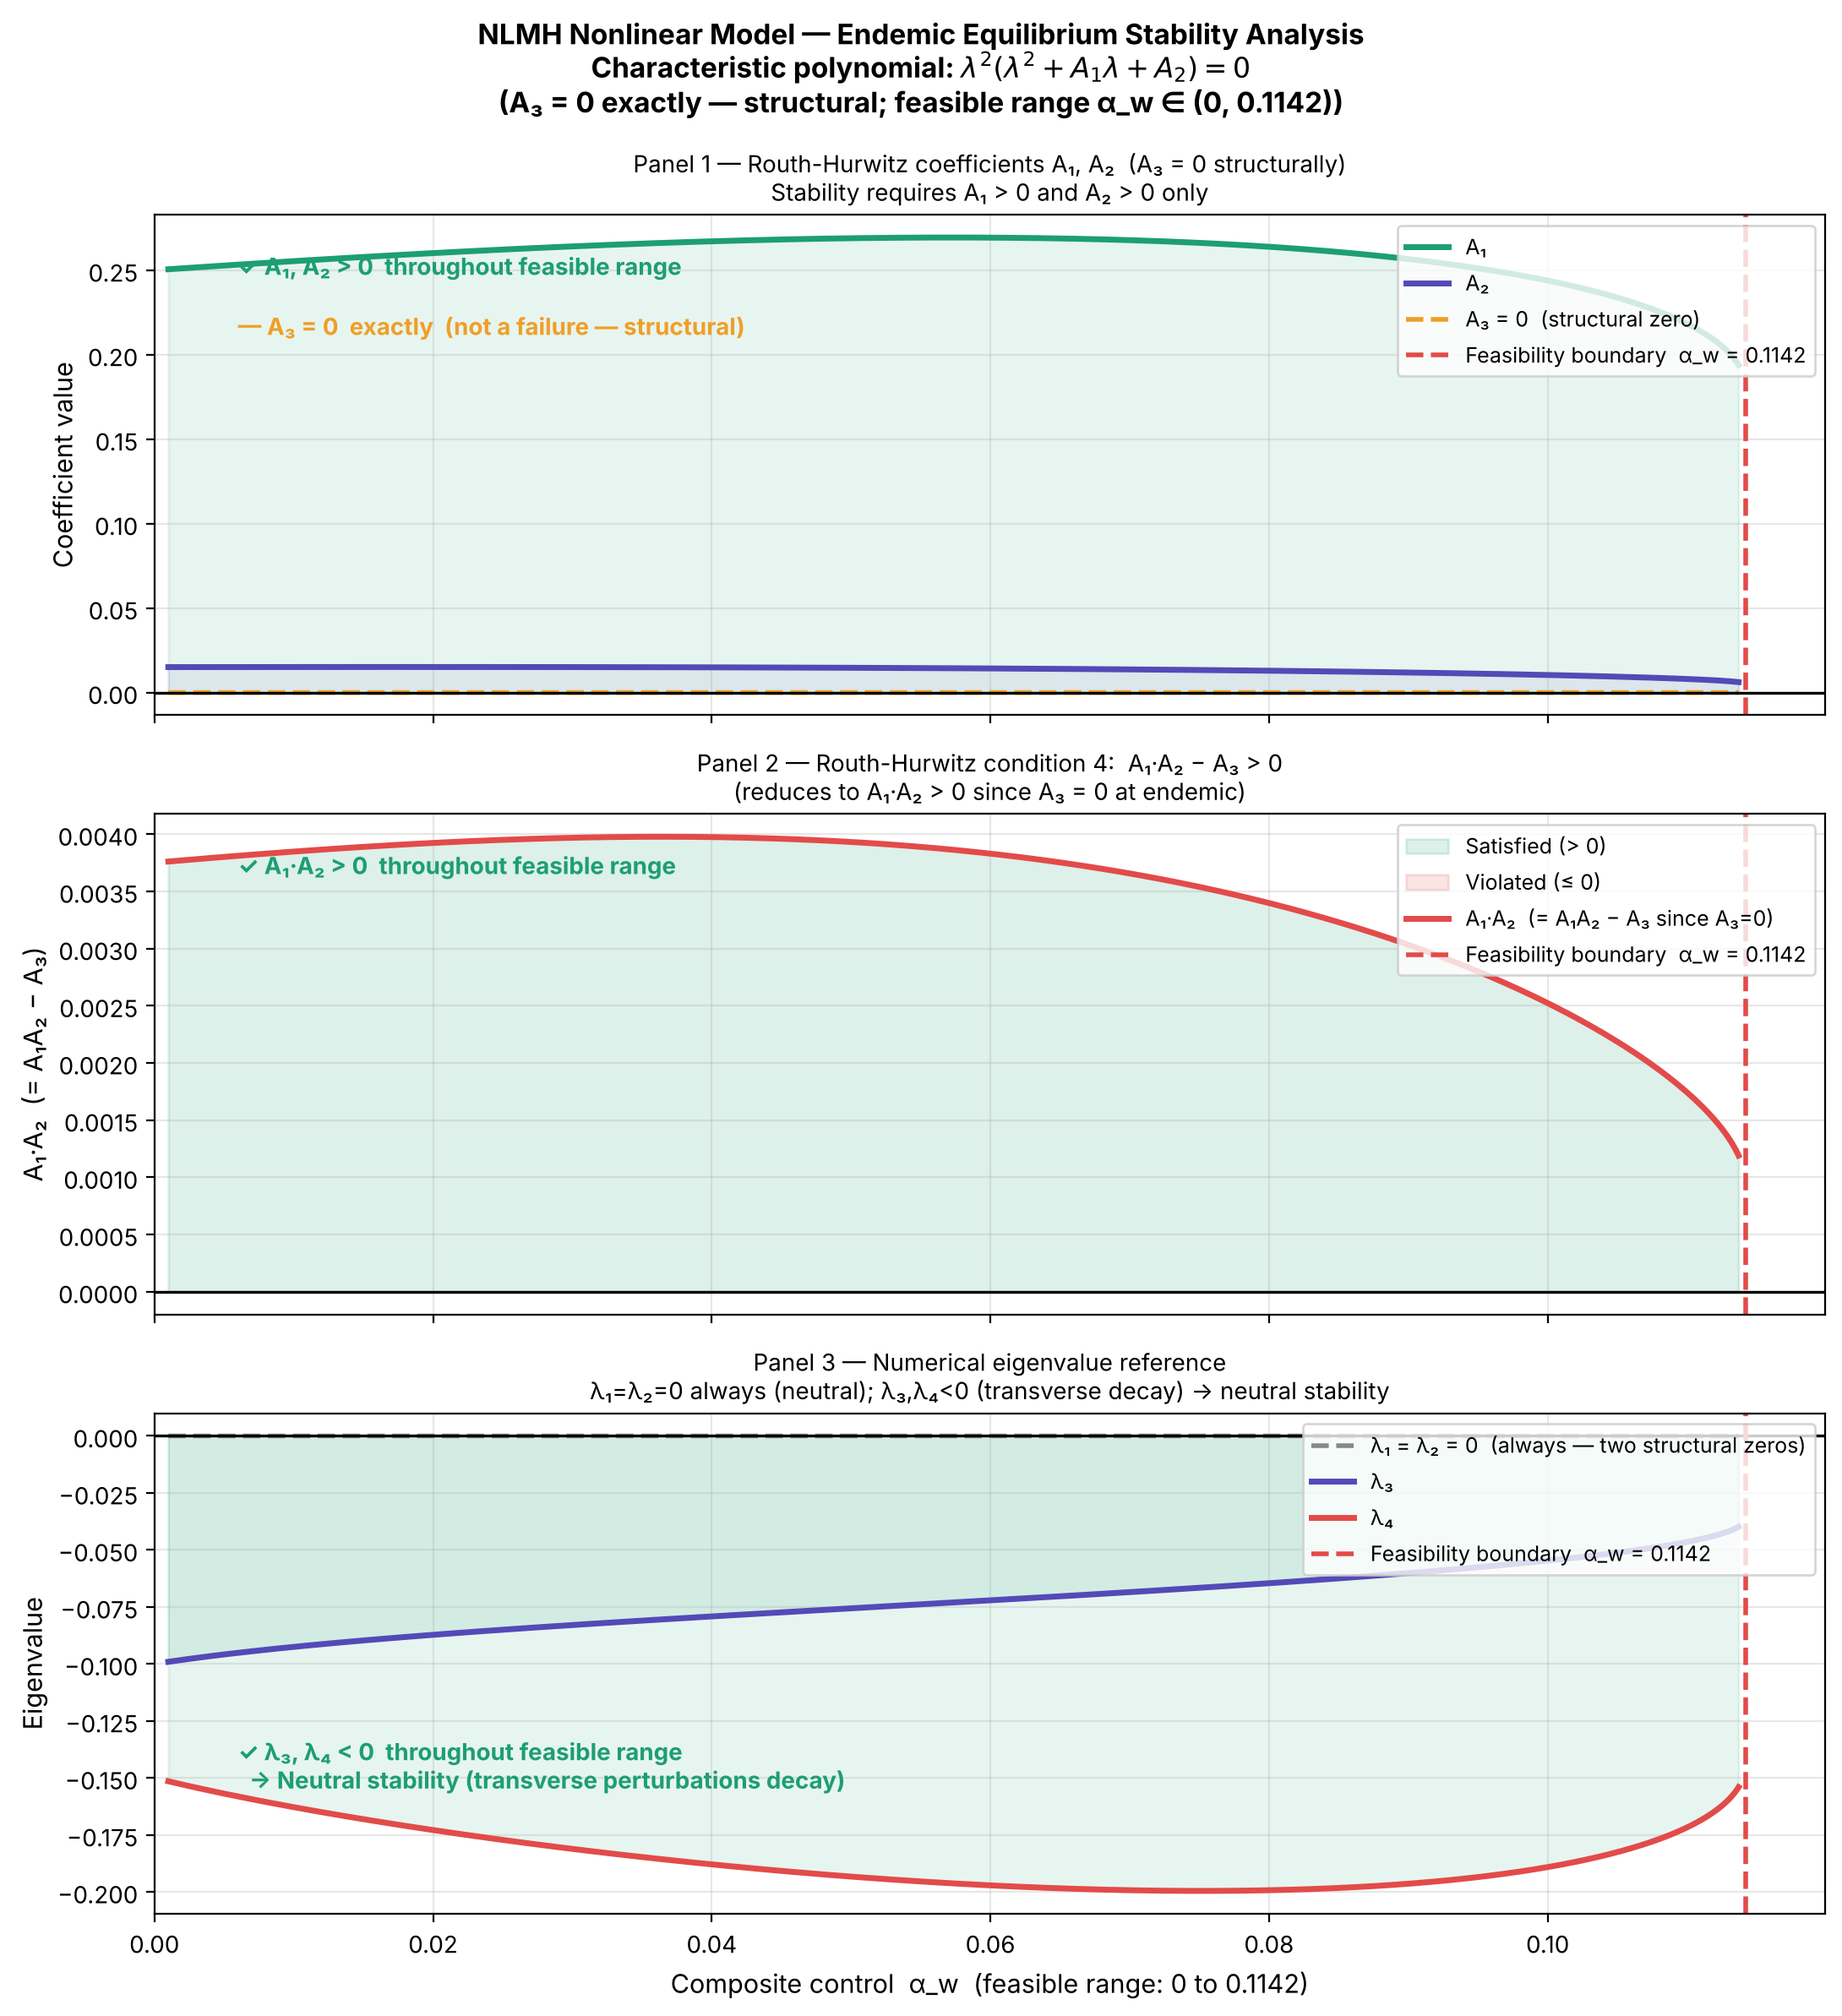


Figure saved: nlmh_stability_nonlinear_endemic.png


In [7]:
# =============================================================================
# FIGURE — 3 PANELS (standardized layout matching DFE and linear scripts)
# Panel 1: A1, A2 combined (A3 = 0 shown as reference line)
# Panel 2: A1*A2 - A3 = A1*A2 (condition 4, since A3=0)
# Panel 3: Numerical eigenvalue reference
# =============================================================================
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
fig.suptitle(
    "NLMH Nonlinear Model — Endemic Equilibrium Stability Analysis\n"
    r"Characteristic polynomial: $\lambda^2(\lambda^2 + A_1\lambda + A_2) = 0$"
    f"\n(A₃ = 0 exactly — structural; feasible range α_w ∈ (0, {alpha_w_max_endemic:.4f}))",
    fontsize=12, fontweight='bold', y=0.99
)

# x-axis limit: show only the feasible range with a small margin
x_lim = (0, alpha_w_max_endemic * 1.05)

# ── Panel 1: A1, A2, A3 ─────────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(alpha_w, A1_arr, color='#1D9E75', linewidth=2.5, label='A₁')
ax1.plot(alpha_w, A2_arr, color='#534AB7', linewidth=2.5, label='A₂')
ax1.plot(alpha_w, A3_endemic, color='#EF9F27', linewidth=2.0,
         linestyle='--', label='A₃ = 0  (structural zero)')
ax1.axhline(0, color='black', linewidth=1.2)
ax1.axvline(alpha_w_max_endemic, color='#E24B4A', linewidth=2.0,
            linestyle='--',
            label=f'Feasibility boundary  α_w = {alpha_w_max_endemic:.4f}')
ax1.fill_between(alpha_w, A1_arr, 0,
                 where=(~np.isnan(A1_arr)) & (A1_arr>0),
                 color='#1D9E75', alpha=0.10)
ax1.fill_between(alpha_w, A2_arr, 0,
                 where=(~np.isnan(A2_arr)) & (A2_arr>0),
                 color='#534AB7', alpha=0.08)
ax1.text(0.05, 0.88, '✓ A₁, A₂ > 0  throughout feasible range',
         transform=ax1.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax1.text(0.05, 0.76, '— A₃ = 0  exactly  (not a failure — structural)',
         transform=ax1.transAxes, color='#EF9F27', fontsize=10, fontweight='bold')
ax1.set_xlim(x_lim)
ax1.set_ylabel("Coefficient value", fontsize=11)
ax1.set_title(
    "Panel 1 — Routh-Hurwitz coefficients A₁, A₂  (A₃ = 0 structurally)\n"
    "Stability requires A₁ > 0 and A₂ > 0 only",
    fontsize=10
)
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Panel 2: A1*A2 (= A1*A2 - A3 since A3=0) ────────────────────────────────
ax2 = axes[1]
RH4_endemic = A1_arr * A2_arr
ax2.fill_between(alpha_w, RH4_endemic, 0,
                 where=(~np.isnan(RH4_endemic)) & (RH4_endemic>0),
                 color='#1D9E75', alpha=0.15, label='Satisfied (> 0)')
ax2.fill_between(alpha_w, RH4_endemic, 0,
                 where=(~np.isnan(RH4_endemic)) & (RH4_endemic<=0),
                 color='#E24B4A', alpha=0.15, label='Violated (≤ 0)')
ax2.plot(alpha_w, RH4_endemic, color='#E24B4A', linewidth=2.5,
         label='A₁·A₂  (= A₁A₂ − A₃ since A₃=0)')
ax2.axhline(0, color='black', linewidth=1.2)
ax2.axvline(alpha_w_max_endemic, color='#E24B4A', linewidth=2.0,
            linestyle='--',
            label=f'Feasibility boundary  α_w = {alpha_w_max_endemic:.4f}')
ax2.text(0.05, 0.88, '✓ A₁·A₂ > 0  throughout feasible range',
         transform=ax2.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax2.set_xlim(x_lim)
ax2.set_ylabel("A₁·A₂  (= A₁A₂ − A₃)", fontsize=11)
ax2.set_title(
    "Panel 2 — Routh-Hurwitz condition 4:  A₁·A₂ − A₃ > 0\n"
    "(reduces to A₁·A₂ > 0 since A₃ = 0 at endemic)",
    fontsize=10
)
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

# ── Panel 3: Numerical eigenvalue reference ──────────────────────────────────
ax3 = axes[2]
ax3.plot(alpha_w, np.zeros_like(alpha_w), color='#888888',
         linewidth=2.0, linestyle='--',
         label='λ₁ = λ₂ = 0  (always — two structural zeros)')
ax3.plot(alpha_w, eig3_arr, color='#534AB7', linewidth=2.5, label='λ₃')
ax3.plot(alpha_w, eig4_arr, color='#E24B4A', linewidth=2.5, label='λ₄')
ax3.axhline(0, color='black', linewidth=1.2)
ax3.axvline(alpha_w_max_endemic, color='#E24B4A', linewidth=2.0,
            linestyle='--',
            label=f'Feasibility boundary  α_w = {alpha_w_max_endemic:.4f}')
ax3.fill_between(alpha_w, eig3_arr, 0,
                 where=(~np.isnan(eig3_arr)) & (eig3_arr<0),
                 color='#1D9E75', alpha=0.10)
ax3.fill_between(alpha_w, eig4_arr, 0,
                 where=(~np.isnan(eig4_arr)) & (eig4_arr<0),
                 color='#1D9E75', alpha=0.10)
ax3.text(0.05, 0.25,
         '✓ λ₃, λ₄ < 0  throughout feasible range\n'
         '  → Neutral stability (transverse perturbations decay)',
         transform=ax3.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax3.set_xlim(x_lim)
ax3.set_xlabel(
    f"Composite control  α_w  "
    f"(feasible range: 0 to {alpha_w_max_endemic:.4f})",
    fontsize=11
)
ax3.set_ylabel("Eigenvalue", fontsize=11)
ax3.set_title(
    "Panel 3 — Numerical eigenvalue reference\n"
    "λ₁=λ₂=0 always (neutral); λ₃,λ₄<0 (transverse decay) → neutral stability",
    fontsize=10
)
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("nlmh_stability_nonlinear_endemic.png", dpi=150)
plt.show()
print("\nFigure saved: nlmh_stability_nonlinear_endemic.png")